# PHẦN 1: TẢI DỮ LIỆU VÀ KIỂM TRA CẤU TRÚC BAN ĐẦU

Cần có file `cardio_train.csv` nằm cùng thư mục với notebook này.
(Nếu chạy trên Google Colab: bấm biểu tượng thư mục bên trái, rồi upload file lên trước khi chạy.)

#### 1.1: Đọc dữ liệu

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

In [23]:
# Đọc file (file cardio dùng dấu ; để ngăn cách các cột)
df_raw = pd.read_csv("cardio_train.csv", sep=";")

# Nếu file dùng dấu phẩy thì đọc lại
if df_raw.shape[1] == 1:
    df_raw = pd.read_csv("cardio_train.csv")

# Đưa tên cột về chữ thường, bỏ khoảng trắng thừa
df_raw.columns = df_raw.columns.str.strip().str.lower()

# Lưu lại vài con số ban đầu để so sánh ở bước 2.5
so_hang_ban_dau = len(df_raw)
so_cot_ban_dau = df_raw.shape[1]
so_thieu_ban_dau = df_raw.isnull().sum().sum()

# Đổi cột age từ ngày sang năm (làm tròn thành số nguyên), ghi đè trực tiếp lên cột age
df_raw["age"] = (df_raw["age"] / 365.25).round(0).astype(int)

df_raw[["age"]].head()

,age
0,50
1,55
2,52
3,48
4,48


#### 1.2: Tổng quan dữ liệu

In [24]:
print("Kích thước:", df_raw.shape[0], "hàng,", df_raw.shape[1], "cột")
print("Các cột:", list(df_raw.columns))

Kích thước: 70000 hàng, 13 cột
Các cột: ['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']


In [25]:
# 5 hàng đầu
df_raw.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,50,2,168,62.0,110,80,1,1,0,0,1,0
1,1,55,1,156,85.0,140,90,3,1,0,0,1,1
2,2,52,1,165,64.0,130,70,3,1,0,0,0,1
3,3,48,2,169,82.0,150,100,1,1,0,0,1,1
4,4,48,1,156,56.0,100,60,1,1,0,0,0,0


In [26]:
# 5 hàng cuối
df_raw.tail()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
69995,99993,53,2,168,76.0,120,80,1,1,1,0,1,0
69996,99995,62,1,158,126.0,140,90,2,2,0,0,1,1
69997,99996,52,2,183,105.0,180,90,3,1,0,1,0,1
69998,99998,61,1,163,72.0,135,80,1,2,0,0,0,1
69999,99999,56,1,170,72.0,120,80,2,1,0,0,1,0


In [27]:
# Kiểu dữ liệu và số giá trị không rỗng của từng cột
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


In [28]:
# Thống kê cơ bản (trung bình, nhỏ nhất, lớn nhất, ...)
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
id,70000.0,49972.419900,28851.302323,0.0,25006.75,50001.5,74889.25,99999.0
age,70000.0,53.303157,6.760171,30.0,48.00,54.0,58.00,65.0
gender,70000.0,1.349571,0.476838,1.0,1.00,1.0,2.00,2.0
height,70000.0,164.359229,8.210126,55.0,159.00,165.0,170.00,250.0
weight,70000.0,74.205690,14.395757,10.0,65.00,72.0,82.00,200.0
ap_hi,70000.0,128.817286,154.011419,-150.0,120.00,120.0,140.00,16020.0
ap_lo,70000.0,96.630414,188.472530,-70.0,80.00,80.0,90.00,11000.0
cholesterol,70000.0,1.366871,0.680250,1.0,1.00,1.0,2.00,3.0
gluc,70000.0,1.226457,0.572270,1.0,1.00,1.0,1.00,3.0
smoke,70000.0,0.088129,0.283484,0.0,0.00,0.0,0.00,1.0


#### 1.3: Biểu đồ tròn cho các cột phân loại

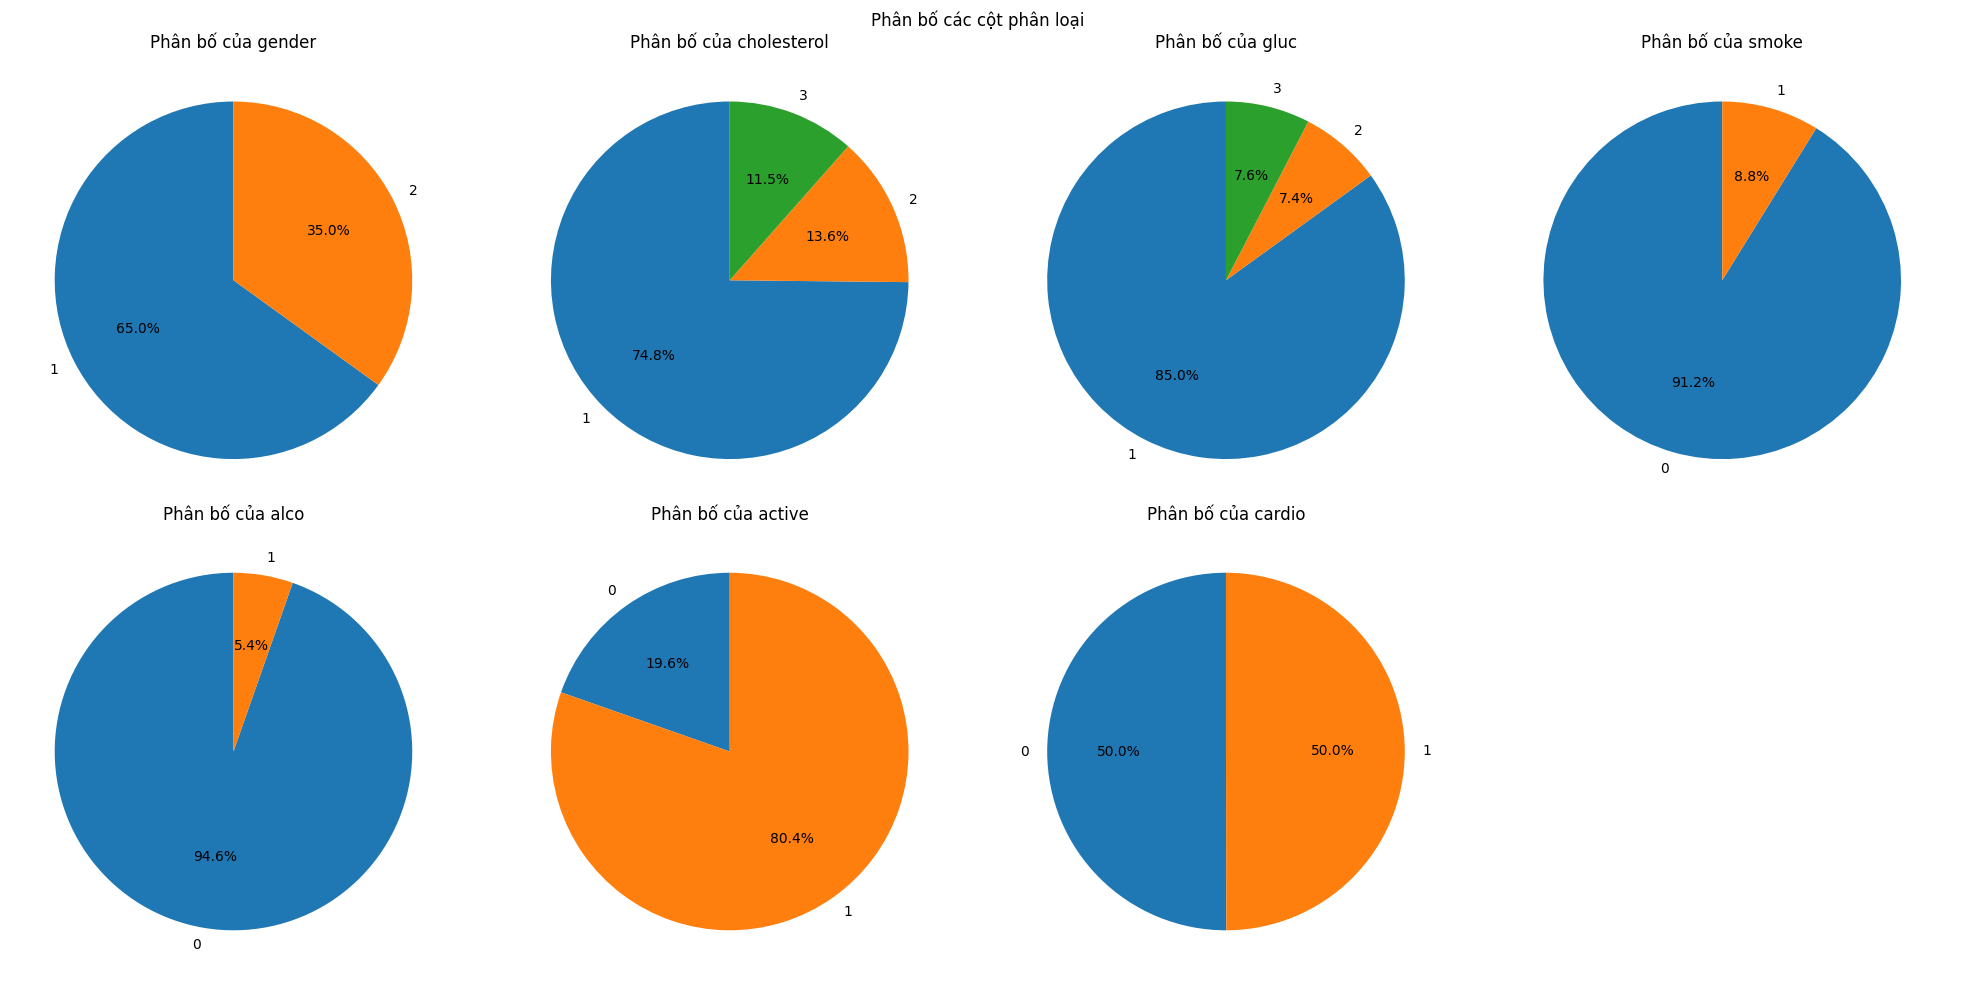

In [29]:
cot_phan_loai = ["gender", "cholesterol", "gluc", "smoke", "alco", "active", "cardio"]

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for i in range(len(cot_phan_loai)):
    cot = cot_phan_loai[i]
    dem = df_raw[cot].value_counts().sort_index()

    axes[i].pie(dem, labels=dem.index, autopct="%1.1f%%", startangle=90)
    axes[i].set_title("Phân bố của " + cot)

# Ô thừa cuối cùng thì ẩn đi
for j in range(len(cot_phan_loai), len(axes)):
    axes[j].axis("off")

plt.suptitle("Phân bố các cột phân loại")
plt.tight_layout()
plt.show()

#### 1.4: Biểu đồ tần suất của huyết áp (ap_hi và ap_lo)

Chia giá trị thành các khoảng rộng 10 (ví dụ 120 đến 130), chỉ vẽ các khoảng có từ 2000 bản ghi trở lên.

ap_hi - nhỏ nhất: -150 - lớn nhất: 16020
ap_lo - nhỏ nhất: -70 - lớn nhất: 11000


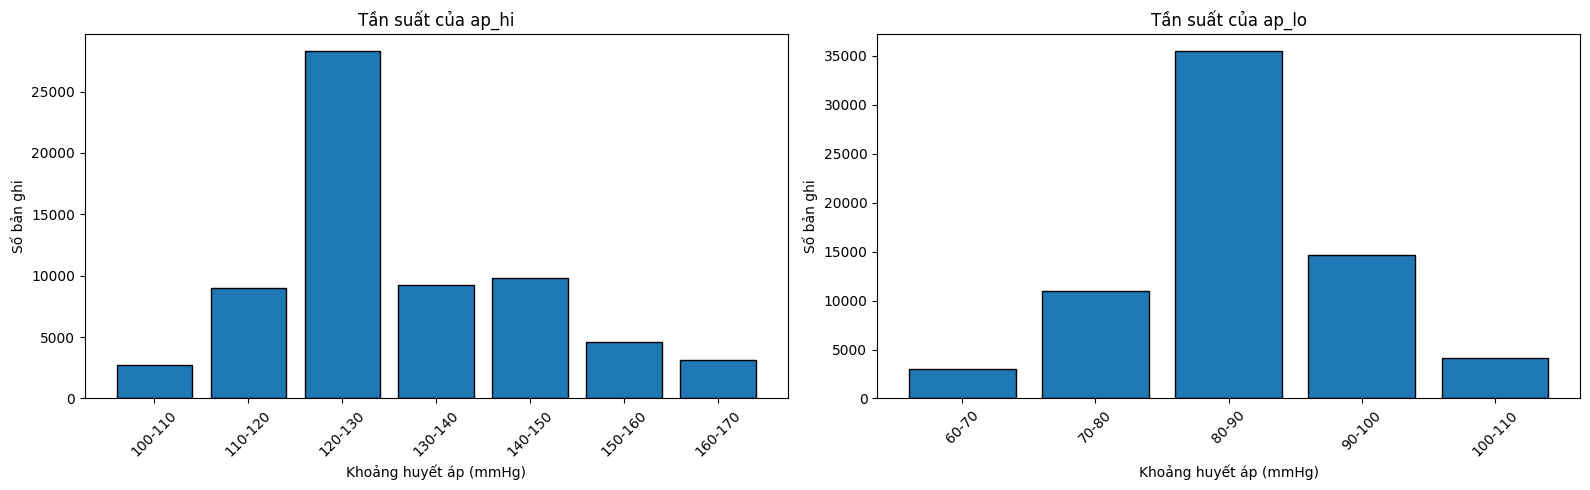

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for i, cot in enumerate(["ap_hi", "ap_lo"]):
    # Ví dụ: 125 -> 120, 138 -> 130
    khoang = df_raw[cot] // 10 * 10

    # Đếm số bản ghi trong mỗi khoảng, chỉ giữ khoảng có từ 2000 bản ghi
    tan_suat = khoang.value_counts().sort_index()
    tan_suat = tan_suat[tan_suat >= 2000]

    # Tạo nhãn dạng "120-130"
    nhan = []
    for k in tan_suat.index:
        nhan.append(str(k) + "-" + str(k + 10))

    axes[i].bar(nhan, tan_suat.values, edgecolor="black")
    axes[i].set_title("Tần suất của " + cot)
    axes[i].set_xlabel("Khoảng huyết áp (mmHg)")
    axes[i].set_ylabel("Số bản ghi")
    axes[i].tick_params(axis="x", rotation=45)

    print(cot, "- nhỏ nhất:", df_raw[cot].min(), "- lớn nhất:", df_raw[cot].max())

plt.tight_layout()
plt.show()

#### 1.5: Biểu đồ phân bố của các cột số còn lại

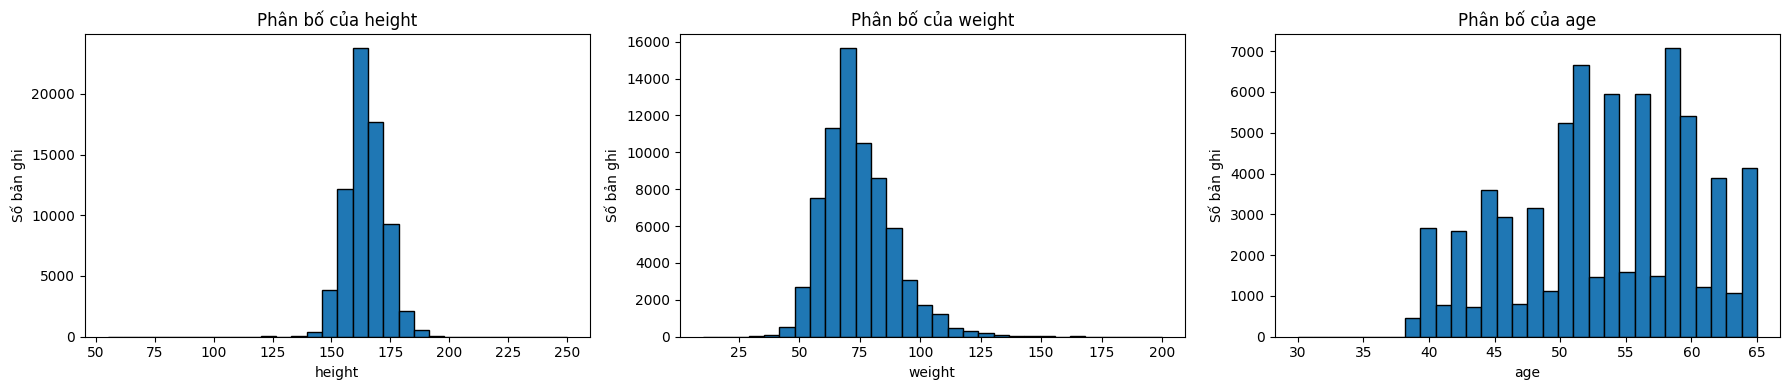

In [31]:
cot_so_con_lai = ["height", "weight", "age"]

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

for i, cot in enumerate(cot_so_con_lai):
    axes[i].hist(df_raw[cot], bins=30, edgecolor="black")
    axes[i].set_title("Phân bố của " + cot)
    axes[i].set_xlabel(cot)
    axes[i].set_ylabel("Số bản ghi")

plt.tight_layout()
plt.show()

# PHẦN 2: LÀM SẠCH VÀ TIỀN XỬ LÝ DỮ LIỆU

#### 2.1: Kiểm tra và xử lý bản ghi trùng lặp

In [32]:
# Trùng cả cột id
so_trung_ca_id = df_raw.duplicated().sum()

# Trùng tất cả các cột trừ id (cùng một bệnh nhân nhưng khác id)
cot_khong_id = list(df_raw.columns)
cot_khong_id.remove("id")
so_trung = df_raw.duplicated(subset=cot_khong_id).sum()

print("Số hàng trùng (tính cả id):", so_trung_ca_id)
print("Số hàng trùng (không tính id):", so_trung)

# Giữ lại hàng xuất hiện đầu tiên, xóa các hàng trùng
df_clean = df_raw.drop_duplicates(subset=cot_khong_id).copy()

print("Số hàng trước:", len(df_raw))
print("Số hàng sau  :", len(df_clean))
print("Số hàng đã xóa:", len(df_raw) - len(df_clean))

Số hàng trùng (tính cả id): 0
Số hàng trùng (không tính id): 3821
Số hàng trước: 70000
Số hàng sau  : 66179
Số hàng đã xóa: 3821


#### 2.2: Kiểm tra và xử lý giá trị thiếu

Bỏ các cột rỗng hoàn toàn, sau đó bỏ các hàng có giá trị thiếu.

In [33]:
print("Số giá trị thiếu của từng cột:")
print(df_clean.isnull().sum())

# Bỏ cột nào rỗng hoàn toàn
df_clean = df_clean.dropna(axis=1, how="all")

# Bỏ hàng nào có ít nhất 1 giá trị thiếu
so_hang_truoc = len(df_clean)
df_clean = df_clean.dropna().copy()

print("Số hàng đã xóa:", so_hang_truoc - len(df_clean))
print("Số hàng còn lại:", len(df_clean))
print("Số giá trị thiếu còn lại:", df_clean.isnull().sum().sum())

Số giá trị thiếu của từng cột:
id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64
Số hàng đã xóa: 0
Số hàng còn lại: 66179
Số giá trị thiếu còn lại: 0


#### 2.3: Chuẩn hóa kiểu dữ liệu và định dạng

In [34]:
# Ép các cột về dạng số (giá trị không chuyển được sẽ thành NaN)
cot_so = ["id", "age", "gender", "height", "weight", "ap_hi", "ap_lo",
          "cholesterol", "gluc", "smoke", "alco", "active", "cardio"]

for cot in cot_so:
    df_clean[cot] = pd.to_numeric(df_clean[cot], errors="coerce")

# Nếu bước trên làm xuất hiện giá trị thiếu thì điền lại:
# cột phân loại điền giá trị xuất hiện nhiều nhất, cột đo điền trung vị
for cot in cot_phan_loai:
    df_clean[cot] = df_clean[cot].fillna(df_clean[cot].mode()[0])

for cot in ["age", "height", "weight", "ap_hi", "ap_lo"]:
    df_clean[cot] = df_clean[cot].fillna(df_clean[cot].median())

In [35]:
# Kiểm tra các cột phân loại có giá trị nào lạ không
ma_hop_le = {
    "gender": [1, 2],
    "cholesterol": [1, 2, 3],
    "gluc": [1, 2, 3],
    "smoke": [0, 1],
    "alco": [0, 1],
    "active": [0, 1],
    "cardio": [0, 1],
}

for cot in ma_hop_le:
    quan_sat = sorted(df_clean[cot].unique().tolist())

    gia_tri_la = []
    for gia_tri in quan_sat:
        if gia_tri not in ma_hop_le[cot]:
            gia_tri_la.append(gia_tri)

    print(cot, "- giá trị quan sát:", quan_sat, "- giá trị lạ:", gia_tri_la)

gender - giá trị quan sát: [1, 2] - giá trị lạ: []
cholesterol - giá trị quan sát: [1, 2, 3] - giá trị lạ: []
gluc - giá trị quan sát: [1, 2, 3] - giá trị lạ: []
smoke - giá trị quan sát: [0, 1] - giá trị lạ: []
alco - giá trị quan sát: [0, 1] - giá trị lạ: []
active - giá trị quan sát: [0, 1] - giá trị lạ: []
cardio - giá trị quan sát: [0, 1] - giá trị lạ: []


In [36]:
# Kiểu dữ liệu của các cột sau khi chuẩn hóa
df_clean.dtypes

id               int64
age              int64
gender           int64
height           int64
weight         float64
ap_hi            int64
ap_lo            int64
cholesterol      int64
gluc             int64
smoke            int64
alco             int64
active           int64
cardio           int64
dtype: object

#### 2.4: Nhận diện và xử lý ngoại lệ ban đầu

Chỉ kiểm tra các cột đo liên tục (không kiểm tra các cột phân loại và cột 0/1).

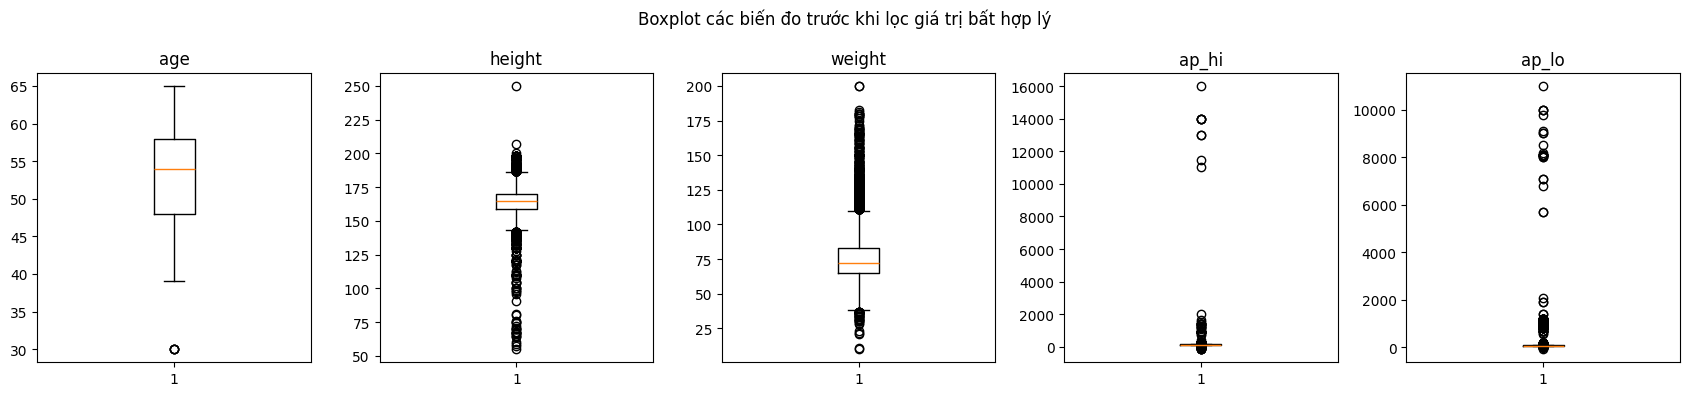

In [37]:
cot_lien_tuc = ["age", "height", "weight", "ap_hi", "ap_lo"]

fig, axes = plt.subplots(1, len(cot_lien_tuc), figsize=(17, 4))

for i in range(len(cot_lien_tuc)):
    cot = cot_lien_tuc[i]
    axes[i].boxplot(df_clean[cot])
    axes[i].set_title(cot)

plt.suptitle("Boxplot các biến đo trước khi lọc giá trị bất hợp lý")
plt.tight_layout()
plt.show()

In [38]:
# Đếm ngoại lệ theo quy tắc 1.5 * IQR
ket_qua = []

for cot in cot_lien_tuc:
    q1 = df_clean[cot].quantile(0.25)
    q3 = df_clean[cot].quantile(0.75)
    iqr = q3 - q1
    can_duoi = q1 - 1.5 * iqr
    can_tren = q3 + 1.5 * iqr
    so_ngoai_le = ((df_clean[cot] < can_duoi) | (df_clean[cot] > can_tren)).sum()

    ket_qua.append({
        "Cột": cot,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Cận dưới": can_duoi,
        "Cận trên": can_tren,
        "Số ngoại lệ IQR": so_ngoai_le,
    })

bang_iqr = pd.DataFrame(ket_qua).set_index("Cột")
bang_iqr.round(2)

,Q1,Q3,IQR,Cận dưới,Cận trên,Số ngoại lệ IQR
Cột,,,,,,
age,48.0,58.0,10.0,33.0,73.0,4
height,159.0,170.0,11.0,142.5,186.5,518
weight,65.0,83.0,18.0,38.0,110.0,1282
ap_hi,120.0,140.0,20.0,90.0,170.0,1434
ap_lo,80.0,90.0,10.0,65.0,105.0,4611


In [39]:
# Chỉ giữ lại các hàng có giá trị nằm trong miền hợp lý
# (dấu & nghĩa là "và", tất cả điều kiện phải cùng đúng)
hop_le = (
    df_clean["age"].between(18, 100)
    & df_clean["height"].between(120, 220)
    & df_clean["weight"].between(30, 250)
    & df_clean["ap_hi"].between(60, 250)
    & df_clean["ap_lo"].between(40, 150)
    & (df_clean["ap_hi"] > df_clean["ap_lo"])   # huyết áp tâm thu phải lớn hơn tâm trương
)

so_hang_truoc = len(df_clean)
so_hang_bat_hop_ly = (~hop_le).sum()   # dấu ~ nghĩa là "không"
df_clean = df_clean[hop_le].copy()

print("Số hàng bất hợp lý đã xóa:", so_hang_bat_hop_ly)
print("Số hàng còn lại:", len(df_clean), "/", so_hang_truoc)

Số hàng bất hợp lý đã xóa: 1388
Số hàng còn lại: 64791 / 66179


#### 2.5: Bảng so sánh trước và sau làm sạch

In [40]:
bang_so_sanh = pd.DataFrame({
    "Chỉ số": [
        "Tổng số hàng",
        "Tổng số cột",
        "Giá trị thiếu",
        "Hàng trùng (không tính id)",
        "Ngoại lệ / giá trị không hợp lý",
    ],
    "Trước làm sạch": [
        so_hang_ban_dau,
        so_cot_ban_dau,
        so_thieu_ban_dau,
        so_trung,
        bang_iqr["Số ngoại lệ IQR"].sum(),
    ],
    "Sau làm sạch": [
        len(df_clean),
        df_clean.shape[1],
        df_clean.isnull().sum().sum(),
        df_clean.duplicated(subset=cot_khong_id).sum(),
        "Đã lọc miền bất hợp lý",
    ],
    "Phương pháp / Lý do": [
        "Bỏ " + str(so_trung) + " hàng trùng và " + str(so_hang_bat_hop_ly) + " hàng bất hợp lý",
        "Đổi cột age từ ngày sang năm",
        "Bỏ cột rỗng và hàng thiếu giá trị (nếu có)",
        "drop_duplicates(), giữ hàng đầu tiên",
        "IQR để nhận diện, chỉ xóa hàng ngoài miền hợp lý hoặc ap_hi <= ap_lo",
    ],
})

bang_so_sanh

,Chỉ số,Trước làm sạch,Sau làm sạch,Phương pháp / Lý do
0,Tổng số hàng,70000,64791,Bỏ 3821 hàng trùng và 1388 hàng bất hợp lý
1,Tổng số cột,13,13,Đổi cột age từ ngày sang năm
2,Giá trị thiếu,0,0,Bỏ cột rỗng và hàng thiếu giá trị (nếu có)
3,Hàng trùng (không tính id),3821,0,"drop_duplicates(), giữ hàng đầu tiên"
4,Ngoại lệ / giá trị không hợp lý,7849,Đã lọc miền bất hợp lý,"IQR để nhận diện, chỉ xóa hàng ngoài miền hợp ..."


#### 2.6: Xuất file dữ liệu đã làm sạch

File `cleaned_cardio.csv` sẽ được lưu cùng thư mục với notebook.

In [41]:
df_clean.to_csv("cleaned_cardio.csv", index=False)

print("Đã lưu file cleaned_cardio.csv")
print("Kích thước:", df_clean.shape[0], "hàng,", df_clean.shape[1], "cột")

# Nếu chạy trên Colab và muốn tải file về máy, bỏ dấu # ở 2 dòng dưới:
# from google.colab import files
# files.download("cleaned_cardio.csv")

Đã lưu file cleaned_cardio.csv
Kích thước: 64791 hàng, 13 cột


In [42]:
# Xem thử vài hàng đầu của dữ liệu đã làm sạch
df_clean.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,50,2,168,62.0,110,80,1,1,0,0,1,0
1,1,55,1,156,85.0,140,90,3,1,0,0,1,1
2,2,52,1,165,64.0,130,70,3,1,0,0,0,1
3,3,48,2,169,82.0,150,100,1,1,0,0,1,1
4,4,48,1,156,56.0,100,60,1,1,0,0,0,0
